<a href="https://colab.research.google.com/github/Zimengyi/ER-Triage-Classification-Using-Bayesian-Networks/blob/main/ER_Triage_Classification_Using_Bayesian_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ER Triage Classification Using Bayesian Networks

## 0. Setup and Data Preparation

### 0.1 Import Libraries

In [143]:
%pip install -q pgmpy

In [144]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from IPython.display import display
from sklearn.model_selection import train_test_split

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator, HillClimbSearch, TreeSearch, BIC
from pgmpy.inference import VariableElimination

RANDOM_SEED = 42

### 0.2 Load the Dataset

This notebook can be run in Google Colab or Jupyter.

Place the provided `data.csv` file in the notebook's working directory.
In Google Colab, an upload prompt is shown if the file is not already
available. Select the original assignment dataset when prompted.

The file is read using a semicolon delimiter and Latin-1 encoding.

In [145]:
from pathlib import Path

data_path = Path("data.csv")

if not data_path.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Place the assignment data.csv in the notebook's "
            "working directory, then rerun this cell."
        ) from exc

    uploaded = files.upload()

    if len(uploaded) != 1:
        raise ValueError("Please upload exactly one assignment CSV file.")

    data_path = Path(next(iter(uploaded)))

print("Dataset file:", data_path.name)

Dataset file: data.csv


In [146]:
df = pd.read_csv(
    data_path,
    sep=";",
    encoding="latin1"
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1267, 24)


,Group,Sex,Age,Patients number per hour,Arrival mode,Injury,Chief_complain,Mental,Pain,NRS_pain,...,BT,Saturation,KTAS_RN,Diagnosis in ED,Disposition,KTAS_expert,Error_group,Length of stay_min,KTAS duration_min,mistriage
0,2,2,71,3,3,2,right ocular pain,1,1,2,...,36.6,100,2,Corneal abrasion,1,4,2,86,"5,00",1
1,1,1,56,12,3,2,right forearm burn,1,1,2,...,36.5,NaN,4,"Burn of hand, firts degree dorsum",1,5,4,64,"3,95",1
2,2,1,68,8,2,2,"arm pain, Lt",1,1,2,...,36.6,98,4,"Fracture of surgical neck of humerus, closed",2,5,4,862,"1,00",1
3,1,2,71,8,1,1,ascites tapping,1,1,3,...,36.5,NaN,4,Alcoholic liver cirrhosis with ascites,1,5,6,108,"9,83",1
4,1,2,58,4,3,1,"distension, abd",1,1,3,...,36.5,NaN,4,Ascites,1,5,8,109,"6,60",1


### 0.3 Inspect the Dataset

Before constructing the Bayesian Networks, the variables and missing values are examined to identify any required preprocessing.

In [147]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Columns:
['Group', 'Sex', 'Age', 'Patients number per hour', 'Arrival mode', 'Injury', 'Chief_complain', 'Mental', 'Pain', 'NRS_pain', 'SBP', 'DBP', 'HR', 'RR', 'BT', 'Saturation', 'KTAS_RN', 'Diagnosis in ED', 'Disposition', 'KTAS_expert', 'Error_group', 'Length of stay_min', 'KTAS duration_min', 'mistriage']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1267 entries, 0 to 1266
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Group                     1267 non-null   int64 
 1   Sex                       1267 non-null   int64 
 2   Age                       1267 non-null   int64 
 3   Patients number per hour  1267 non-null   int64 
 4   Arrival mode              1267 non-null   int64 
 5   Injury                    1267 non-null   int64 
 6   Chief_complain            1267 non-null   object
 7   Mental                    1267 non-null   int64 
 8   Pain          

In [148]:
print("Missing values:")
display(df.isna().sum().to_frame("Missing"))

Missing values:


,Missing
Group,0
Sex,0
Age,0
Patients number per hour,0
Arrival mode,0
Injury,0
Chief_complain,0
Mental,0
Pain,0
NRS_pain,0


### 0.4 Data Cleaning and Recoding

Integer-coded categorical variables are converted into descriptive categories according to the mappings provided in the assignment. Invalid values in continuous variables are converted to missing values before discretization.

KTAS expert levels 1–3 are classified as **Emergency**, while levels 4–5 are classified as **Non-Emergency**.

In [149]:
# Keep the original DataFrame unchanged
data = df.copy()

# Convert continuous variables to numeric.
# Invalid values such as "??" are converted to NaN.
numeric_columns = [
    "Age",
    "SBP",
    "DBP",
    "HR",
    "RR",
    "BT",
    "NRS_pain"
]

for col in numeric_columns:
    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

print("Missing values after numeric conversion:")
print(data[numeric_columns].isna().sum())

Missing values after numeric conversion:
Age           0
SBP          25
DBP          29
HR           20
RR           22
BT           18
NRS_pain    556
dtype: int64


In [150]:
# Sex
data["Sex"] = data["Sex"].map({
    1: "female",
    2: "male"
})

# Arrival mode
data["Arrival_mode"] = data["Arrival mode"].map({
    1: "walking",
    2: "public_ambulance",
    3: "private_vehicle",
    4: "private_ambulance",
    5: "other",
    6: "other",
    7: "other"
})

# Mental status
data["Mental"] = data["Mental"].map({
    1: "alert",
    2: "verbal",
    3: "pain",
    4: "unresponsive"
})

# Injury
data["Injury"] = data["Injury"].map({
    1: "no",
    2: "yes"
})

# Pain
data["Pain"] = data["Pain"].map({
    0: "no",
    1: "yes"
})

# Disposition
data["Disposition"] = data["Disposition"].map({
    1: "discharge",
    2: "admission",
    3: "critical",
    4: "discharge",
    5: "transfer",
    6: "critical",
    7: "critical"
})

# Binary KTAS expert outcome
data["KTAS_expert"] = data["KTAS_expert"].map({
    1: "emergency",
    2: "emergency",
    3: "emergency",
    4: "non_emergency",
    5: "non_emergency"
})

In [151]:
print("Pain:")
print(data["Pain"].value_counts(dropna=False))

print("\nInjury:")
print(data["Injury"].value_counts(dropna=False))

print("\nMental status:")
print(data["Mental"].value_counts(dropna=False))

print("\nArrival mode:")
print(data["Arrival_mode"].value_counts(dropna=False))

print("\nKTAS expert:")
print(data["KTAS_expert"].value_counts(dropna=False))

Pain:
Pain
yes    714
no     553
Name: count, dtype: int64

Injury:
Injury
no     1023
yes     244
Name: count, dtype: int64

Mental status:
Mental
alert           1187
verbal            39
pain              28
unresponsive      13
Name: count, dtype: int64

Arrival mode:
Arrival_mode
private_vehicle      753
public_ambulance     266
private_ambulance    155
walking               79
other                 14
Name: count, dtype: int64

KTAS expert:
KTAS_expert
emergency        733
non_emergency    534
Name: count, dtype: int64


### 0.5 Discretize Continuous Variables

Continuous variables are discretized into clinically meaningful categories using the intervals specified in the assignment.

In [152]:
# Age
data["Age"] = pd.cut(
    data["Age"],
    bins=[0, 35, 65, 100],
    labels=["young", "middle", "old"]
)

# Systolic blood pressure
data["SBP"] = pd.cut(
    data["SBP"],
    bins=[0, 90, 120, 140, 300],
    labels=["low", "normal", "elevated", "high"]
)

# Heart rate
data["HR"] = pd.cut(
    data["HR"],
    bins=[0, 60, 100, 300],
    labels=["low", "normal", "high"]
)

# Respiratory rate
data["RR"] = pd.cut(
    data["RR"],
    bins=[0, 12, 20, 60],
    labels=["low", "normal", "high"]
)

# Body temperature
data["BT"] = pd.cut(
    data["BT"],
    bins=[0, 36, 37.5, 42],
    labels=["low", "normal", "fever"]
)

# Numeric pain score
data["NRS_pain"] = pd.cut(
    data["NRS_pain"],
    bins=[0, 3, 7, 10],
    labels=["mild", "moderate", "severe"]
)

# Diastolic blood pressure
data["DBP"] = pd.cut(
    data["DBP"],
    bins=[0, 60, 80, 90, 200],
    labels=["low", "normal", "elevated", "high"]
)

In [153]:
discretized_columns = [
    "Age",
    "SBP",
    "HR",
    "RR",
    "BT",
    "NRS_pain",
    "DBP"
]

for col in discretized_columns:
    print(f"\n{col}")
    print(data[col].value_counts(dropna=False))


Age
Age
middle    533
old       443
young     291
Name: count, dtype: int64

SBP
SBP
normal      452
high        413
elevated    342
low          35
NaN          25
Name: count, dtype: int64

HR
HR
normal    973
high      200
low        74
NaN        20
Name: count, dtype: int64

RR
RR
normal    1139
high       106
NaN         22
low          0
Name: count, dtype: int64

BT
BT
normal    995
low       194
fever      60
NaN        18
Name: count, dtype: int64

NRS_pain
NRS_pain
NaN         556
moderate    380
mild        318
severe       13
Name: count, dtype: int64

DBP
DBP
normal      585
high        263
elevated    224
low         166
NaN          29
Name: count, dtype: int64


### 0.6 Prepare Complaint Category

The dataset contains a free-text `Chief_complain` variable rather than a pre-defined complaint category. A categorical complaint variable is therefore required before it can be incorporated into the Bayesian Network.

The following inspection determines the number and frequency of unique chief complaints.

In [154]:
print(
    "Number of unique chief complaints:",
    data["Chief_complain"].nunique()
)

display(
    data["Chief_complain"]
    .value_counts()
    .head(30)
    .to_frame("Count")
)

Number of unique chief complaints: 417


,Count
Chief_complain,
abd pain,72
dyspnea,60
dizziness,59
fever,45
ant. chest pain,44
Open Wound,31
headache,30
mental change,22
epigastric pain,22


In [155]:
def categorize_complaint(complaint):

    # Handle missing values
    if pd.isna(complaint):
        return "general_other"

    text = str(complaint).lower().strip()

    # Abdominal complaints
    if any(word in text for word in [
        "abd", "abdominal", "epigastric",
        "ruq", "luq", "rlq", "llq",
        "flank"
    ]):
        return "abdominal"

    # Chest / cardiovascular complaints
    elif any(word in text for word in [
        "chest", "palpitation", "cardiac",
        "heart"
    ]):
        return "chest_cardiovascular"

    # Respiratory complaints
    elif any(word in text for word in [
        "dyspnea", "shortness of breath",
        "sob", "breath", "respiratory",
        "cough"
    ]):
        return "respiratory"

    # Neurologic complaints
    elif any(word in text for word in [
        "headache", "dizziness", "dizzy",
        "mental change", "syncope",
        "seizure", "dysarthria",
        "weakness", "paralysis",
        "numbness", "vertigo"
    ]):
        return "neurologic"

    # Bleeding complaints
    elif any(word in text for word in [
        "hematemesis", "hematochezia",
        "melena", "bleeding", "bleed",
        "hemoptysis"
    ]):
        return "bleeding"

    # Fever / infectious complaints
    elif any(word in text for word in [
        "fever", "febrile", "chill",
        "infection"
    ]):
        return "fever_infection"

    # Trauma / injury complaints
    elif any(word in text for word in [
        "injury", "wound", "laceration",
        "trauma", "fracture", "burn",
        "contusion", "sprain", "fall"
    ]):
        return "trauma_injury"

    # Musculoskeletal pain
    elif any(word in text for word in [
        "back pain", "neck pain",
        "shoulder pain", "arm pain",
        "leg pain", "knee pain",
        "hip pain", "ankle pain",
        "joint pain"
    ]):
        return "musculoskeletal_pain"

    # Gastrointestinal complaints
    elif any(word in text for word in [
        "vomiting", "nausea", "diarrhea",
        "constipation"
    ]):
        return "gastrointestinal"

    # Genitourinary / gynecologic complaints
    elif any(word in text for word in [
        "urine", "urinary", "dysuria",
        "vaginal", "pelvic",
        "testicular", "scrotal"
    ]):
        return "genitourinary"

    # Skin / allergic complaints
    elif any(word in text for word in [
        "rash", "urticaria", "allergy",
        "allergic", "itch", "swelling"
    ]):
        return "skin_allergy"

    # Remaining complaints
    else:
        return "general_other"

In [156]:
data["Complaint_category"] = (
    data["Chief_complain"]
    .apply(categorize_complaint)
)

print(
    "Number of complaint categories:",
    data["Complaint_category"].nunique()
)

display(
    data["Complaint_category"]
    .value_counts()
    .to_frame("Count")
)

Number of complaint categories: 12


,Count
Complaint_category,
general_other,303
abdominal,223
neurologic,217
chest_cardiovascular,111
trauma_injury,108
respiratory,71
bleeding,54
musculoskeletal_pain,50
fever_infection,49


### 0.7 Create the Final Bayesian Network Dataset

Only variables relevant to the Bayesian Network are retained. Observations containing missing values in these variables are excluded from model estimation.

In [157]:
bn_columns = [
    "Age",
    "Complaint_category",
    "Mental",
    "Pain",
    "Injury",
    "Arrival_mode",
    "SBP",
    "HR",
    "RR",
    "BT",
    "KTAS_expert"
]

bn_data = data[bn_columns].copy()

print("Observations before removing missing values:", len(bn_data))

bn_data = bn_data.dropna()

print("Observations used for Bayesian Network analysis:", len(bn_data))

display(bn_data.head())

Observations before removing missing values: 1267
Observations used for Bayesian Network analysis: 1236


,Age,Complaint_category,Mental,Pain,Injury,Arrival_mode,SBP,HR,RR,BT,KTAS_expert
0,old,general_other,alert,yes,yes,private_vehicle,high,normal,normal,normal,non_emergency
1,middle,trauma_injury,alert,yes,yes,private_vehicle,elevated,low,normal,normal,non_emergency
2,old,musculoskeletal_pain,alert,yes,yes,public_ambulance,elevated,high,normal,normal,non_emergency
3,old,general_other,alert,yes,no,walking,elevated,normal,normal,normal,non_emergency
4,middle,abdominal,alert,yes,no,private_vehicle,normal,normal,normal,normal,non_emergency


# Problem 1 — Building a Bayesian Network

## 1(a) Construct the Clinician-Informed Bayesian Network

The first Bayesian Network is based on relationships specified by clinicians. The network represents assumed probabilistic dependencies among demographic characteristics, presenting symptoms, physiological measurements, and the expert-assigned emergency classification.

In [158]:
clinician_edges = [
    ("Age", "SBP"),
    ("Age", "KTAS_expert"),

    ("Complaint_category", "Pain"),
    ("Complaint_category", "KTAS_expert"),

    ("Mental", "Arrival_mode"),
    ("Mental", "KTAS_expert"),

    ("Arrival_mode", "KTAS_expert"),
    ("Pain", "KTAS_expert"),
    ("SBP", "KTAS_expert"),
    ("HR", "KTAS_expert"),
    ("RR", "KTAS_expert"),
    ("BT", "KTAS_expert"),
    ("Injury", "KTAS_expert")
]

clinician_model = DiscreteBayesianNetwork(
    clinician_edges
)

print("Number of nodes:", len(clinician_model.nodes()))
print("Number of edges:", len(clinician_model.edges()))
print("Edges:")
print(list(clinician_model.edges()))

Number of nodes: 11
Number of edges: 13
Edges:
[('Age', 'SBP'), ('Age', 'KTAS_expert'), ('SBP', 'KTAS_expert'), ('Complaint_category', 'Pain'), ('Complaint_category', 'KTAS_expert'), ('Pain', 'KTAS_expert'), ('Mental', 'Arrival_mode'), ('Mental', 'KTAS_expert'), ('Arrival_mode', 'KTAS_expert'), ('HR', 'KTAS_expert'), ('RR', 'KTAS_expert'), ('BT', 'KTAS_expert'), ('Injury', 'KTAS_expert')]


### Verify the DAG

In [159]:
is_dag = nx.is_directed_acyclic_graph(
    clinician_model
)

print("Is the network a valid DAG?", is_dag)

Is the network a valid DAG? True


### Visualize the Clinician-Informed Network

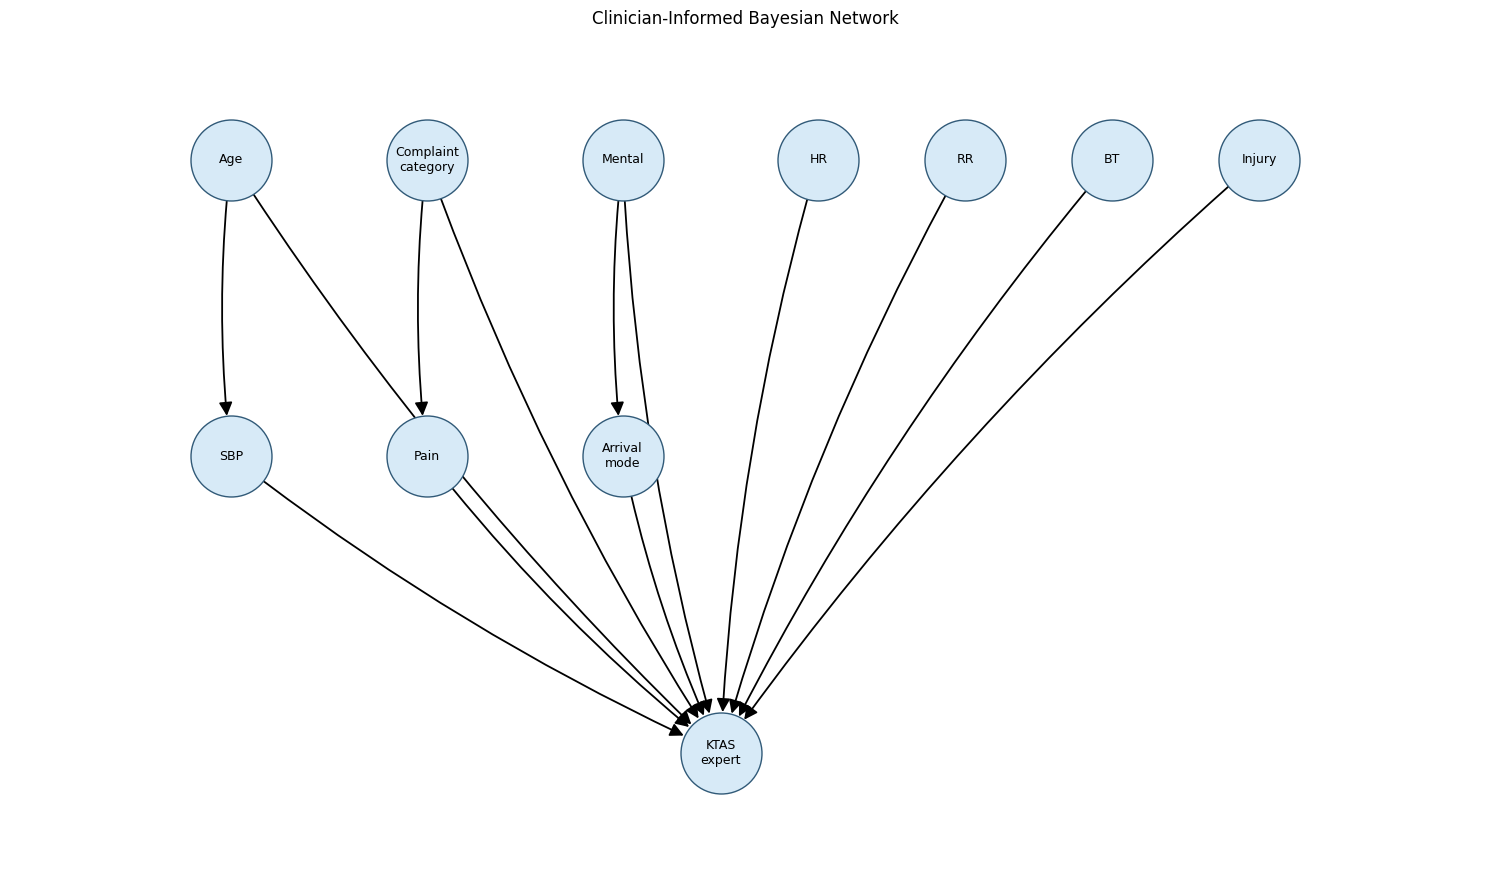

In [160]:
def draw_bn(model, title, pos=None):
    G = nx.DiGraph()
    G.add_nodes_from(model.nodes())
    G.add_edges_from(model.edges())

    if pos is None:
        pos = nx.circular_layout(G)

    labels = {
        node: node.replace("_", "\n")
        for node in G.nodes()
    }

    fig, ax = plt.subplots(figsize=(15, 9))

    nx.draw_networkx_nodes(
        G, pos,
        node_size=3400,
        node_color="#D7EAF7",
        edgecolors="#315A78",
        ax=ax
    )

    nx.draw_networkx_labels(
        G, pos,
        labels=labels,
        font_size=9,
        ax=ax
    )

    nx.draw_networkx_edges(
        G, pos,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=20,
        node_size=3400,
        connectionstyle="arc3,rad=0.06",
        width=1.3,
        ax=ax
    )

    ax.set_title(title)
    ax.margins(0.15)
    ax.axis("off")
    plt.tight_layout()
    plt.show()


clinician_pos = {
    "Age": (-4, 2),
    "Complaint_category": (-2, 2),
    "Mental": (0, 2),
    "HR": (2, 2),
    "RR": (3.5, 2),
    "BT": (5, 2),
    "Injury": (6.5, 2),
    "SBP": (-4, 0),
    "Pain": (-2, 0),
    "Arrival_mode": (0, 0),
    "KTAS_expert": (1, -2)
}

draw_bn(
    clinician_model,
    "Clinician-Informed Bayesian Network",
    pos=clinician_pos
)

### Interpretation of the Network Structure

The clinician-informed Bayesian Network represents the relationships specified in the assignment. Age influences both systolic blood pressure (SBP) and the final KTAS classification. Complaint category influences pain and KTAS classification, while mental status influences arrival mode and KTAS classification. Arrival mode, pain, SBP, HR, RR, BT, and injury provide additional direct information about emergency status.

The directed structure represents probabilistic dependencies and conditional independence assumptions. The arrows describe the factorization assumed by the Bayesian Network and should not necessarily be interpreted as causal relationships.

## 1(b) Learn Conditional Probability Tables

The conditional probability distributions are estimated from the observed data. Because `KTAS_expert` has many parent variables, the number of possible parent-state combinations is large relative to the sample size. Bayesian parameter estimation with smoothing is therefore used to reduce the problem of zero-probability estimates for combinations that are rare or not observed in the dataset.

In [161]:
from pgmpy.estimators import BayesianEstimator

# Create a Bayesian parameter estimator
estimator = BayesianEstimator(
    clinician_model,
    bn_data
)

# Estimate the CPT for each node using a BDeu prior
cpds = estimator.get_parameters(
    prior_type="BDeu",
    equivalent_sample_size=10
)

# Add the estimated CPTs to the Bayesian Network
clinician_model.add_cpds(*cpds)

# Check whether the fitted model is valid
print(
    "Model fitted successfully:",
    clinician_model.check_model()
)

/tmp/ipykernel_3821/3408464553.py:4: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(


Model fitted successfully: True


### Conditional Probability Tables

In [162]:
def cpd_to_dataframe(cpd):
    variables = list(cpd.variables)
    child = variables[0]
    parents = variables[1:]

    if parents:
        columns = pd.MultiIndex.from_product(
            [cpd.state_names[parent] for parent in parents],
            names=parents
        )
    else:
        columns = pd.Index(
            ["Marginal probability"],
            name="Distribution"
        )

    return pd.DataFrame(
        cpd.get_values(),
        index=pd.Index(
            cpd.state_names[child],
            name=child
        ),
        columns=columns
    )

In [163]:
print("CPT for Age")
display(
    cpd_to_dataframe(
        clinician_model.get_cpds("Age")
    ).round(6)
)

CPT for Age


Distribution,Marginal probability
Age,
middle,0.420011
old,0.344569
young,0.235420


In [164]:
print("CPT for SBP given Age")
display(
    cpd_to_dataframe(
        clinician_model.get_cpds("SBP")
    ).T.round(6)
)

CPT for SBP given Age


SBP,elevated,high,low,normal
Age,,,,
middle,0.301592,0.324522,0.020701,0.353185
old,0.246506,0.376941,0.041537,0.335016
young,0.272159,0.282386,0.019886,0.425568


In [165]:
print("CPT for Pain given Complaint_category")
display(
    cpd_to_dataframe(
        clinician_model.get_cpds("Pain")
    ).T.round(6)
)

CPT for Pain given Complaint_category


Pain,no,yes
Complaint_category,,
abdominal,0.051234,0.948766
bleeding,0.825077,0.174923
chest_cardiovascular,0.139098,0.860902
fever_infection,0.730769,0.269231
gastrointestinal,0.643541,0.356459
general_other,0.503438,0.496562
genitourinary,0.542254,0.457746
musculoskeletal_pain,0.028428,0.971572
neurologic,0.739425,0.260575


The CPT for Age represents the marginal distribution of age groups because Age has no parents in the network. The CPT for SBP represents \(P(SBP \mid Age)\), showing how the distribution of systolic blood pressure varies across age groups. The CPT for Pain represents \(P(Pain \mid Complaint\ Category)\), showing how reported pain varies across complaint categories.

### CPT for KTAS_expert

`KTAS_expert` has multiple parent variables in the clinician-informed network. Consequently, its complete CPT contains a very large number of possible parent-state combinations. The CPT is estimated as part of the fitted Bayesian Network, but only a small portion is displayed below for readability.

In [166]:
ktas_parents = list(
    clinician_model.predecessors(
        "KTAS_expert"
    )
)

print("Parents of KTAS_expert:")
print(ktas_parents)

print(
    "\nNumber of parents:",
    len(ktas_parents)
)

Parents of KTAS_expert:
['Age', 'Complaint_category', 'Mental', 'Arrival_mode', 'Pain', 'SBP', 'HR', 'RR', 'BT', 'Injury']

Number of parents: 10


In [167]:
ktas_cpd = clinician_model.get_cpds("KTAS_expert")

# Each row identifies one complete parent-state configuration.
ktas_table = cpd_to_dataframe(ktas_cpd).T
parents = list(ktas_cpd.variables[1:])

# Count the observations supporting each configuration.
observed_counts = (
    bn_data
    .groupby(parents, observed=True)
    .size()
)

ktas_table["Observed count"] = (
    observed_counts
    .reindex(ktas_table.index, fill_value=0)
    .astype(int)
)

print("Number of parent configurations:", len(ktas_table))
print(
    "Configurations observed in the data:",
    int((ktas_table["Observed count"] > 0).sum())
)

print("\nFive most frequently observed configurations:")
display(
    ktas_table
    .sort_values("Observed count", ascending=False)
    .head(5)
    .reset_index()
    .round(6)
)

print("\nThree unobserved configurations:")
display(
    ktas_table.loc[ktas_table["Observed count"] == 0]
    .head(3)
    .reset_index()
    .round(6)
)

Number of parent configurations: 207360
Configurations observed in the data: 785

Five most frequently observed configurations:


KTAS_expert,Age,Arrival_mode,BT,Complaint_category,HR,Injury,Mental,Pain,RR,SBP,emergency,non_emergency,Observed count
0,middle,private_vehicle,normal,abdominal,normal,no,alert,yes,normal,normal,0.400000,0.600000,20
1,young,private_vehicle,normal,abdominal,normal,no,alert,yes,normal,normal,0.666666,0.333334,15
2,middle,private_vehicle,normal,abdominal,normal,no,alert,yes,normal,high,0.384616,0.615384,13
3,old,private_vehicle,normal,neurologic,normal,no,alert,no,normal,high,0.846153,0.153847,13
4,young,private_vehicle,normal,trauma_injury,normal,yes,alert,yes,normal,normal,0.000002,0.999998,12



Three unobserved configurations:


KTAS_expert,Age,Arrival_mode,BT,Complaint_category,HR,Injury,Mental,Pain,RR,SBP,emergency,non_emergency,Observed count
0,middle,other,fever,abdominal,high,no,alert,no,high,elevated,0.5,0.5,0
1,middle,other,fever,abdominal,high,no,alert,no,high,high,0.5,0.5,0
2,middle,other,fever,abdominal,high,no,alert,no,high,low,0.5,0.5,0


Each displayed row identifies a complete combination of the ten parent
variables of `KTAS_expert`. The `emergency` and `non_emergency` columns
give the conditional probabilities for that combination and sum to one.
The observed count indicates how many records support the combination.

The full CPT is retained in the fitted model. For readability, the tables
show frequently observed configurations and examples of unobserved
configurations.

A BDeu prior with equivalent sample size 10 is used for parameter
estimation. For an unobserved parent configuration, the symmetric prior
produces probabilities of 0.5 for each outcome. These values reflect the
prior in the absence of observations for that configuration.

## 1(c) Conditional Independence

### Relationship 1: Arrival Mode and Age given Mental Status

Arrival mode and Age are conditionally independent given Mental status.
Every path connecting them passes through a collider at `KTAS_expert`.
Because neither this collider nor any descendant is observed, these
paths remain blocked.

$$
Arrival\_mode \perp Age \mid Mental
$$

### Relationship 2: SBP and Pain given Age and Complaint Category

SBP and Pain are conditionally independent given Age and Complaint
category. Paths through either conditioned parent are blocked, while
paths through the unobserved collider `KTAS_expert` also remain blocked.

$$
SBP \perp Pain \mid Age,\ Complaint\_category
$$

These statements follow from d-separation in the specified graph.

# Problem 2 — Bayesian Inference and Diagnosis

## 2(a) Baseline Probability of Emergency Triage

Variable elimination is used to calculate the marginal probability of Emergency classification without providing any patient-specific evidence. This model-based probability is compared with the observed proportion of Emergency cases in the data used to fit the network.

In [168]:
inference = VariableElimination(
    clinician_model
)

baseline = inference.query(
    variables=["KTAS_expert"]
)

print("Baseline distribution:")
print(baseline)

Baseline distribution:
+----------------------------+--------------------+
| KTAS_expert                |   phi(KTAS_expert) |
+============================+====================+
| KTAS_expert(emergency)     |             0.5228 |
+----------------------------+--------------------+
| KTAS_expert(non_emergency) |             0.4772 |
+----------------------------+--------------------+


In [169]:
p_baseline = baseline.get_value(
    KTAS_expert="emergency"
)

observed_emergency = (
    bn_data["KTAS_expert"] == "emergency"
).mean()

baseline_comparison = pd.DataFrame({
    "Measure": [
        "Bayesian Network",
        "Observed Data"
    ],
    "P(Emergency)": [
        p_baseline,
        observed_emergency
    ]
})

display(baseline_comparison)

print(
    "Difference:",
    round(
        p_baseline - observed_emergency,
        4
    )
)

,Measure,P(Emergency)
0,Bayesian Network,0.522786
1,Observed Data,0.571197


Difference: -0.0484


### Interpretation

The fitted Bayesian Network gives a baseline probability of Emergency classification of 0.5228 (52.28%). In comparison, 706 of the 1,236 complete observations in the analysis dataset were classified as Emergency, giving an observed proportion of 0.5712 (57.12%).

Therefore, the model-based baseline probability is approximately 4.84 percentage points lower than the observed proportion.

The two values are not identical because the Bayesian Network probability is obtained by marginalizing over the fitted conditional probability distributions rather than simply calculating the empirical frequency of the outcome. In addition, Bayesian parameter estimation with a BDeu prior was used to smooth the CPTs. This is particularly relevant for `KTAS_expert`, which has many parent variables and therefore a large number of possible parent-state combinations relative to the sample size. Smoothing assigns probability mass to sparse or unobserved configurations, which can cause the model-implied marginal probability to differ from the raw observed proportion.

## 2(b) Patient Diagnosis

Consider a patient with the following observed characteristics:

- Mental status: Alert
- SBP: High
- HR: High
- RR: High
- Pain: Yes
- Injury: No

The posterior probability of Emergency classification is calculated using variable elimination.

In [170]:
patient_evidence = {
    "Mental": "alert",
    "SBP": "high",
    "HR": "high",
    "RR": "high",
    "Pain": "yes",
    "Injury": "no"
}

posterior_full = inference.query(
    variables=["KTAS_expert"],
    evidence=patient_evidence
)

print(posterior_full)

+----------------------------+--------------------+
| KTAS_expert                |   phi(KTAS_expert) |
+============================+====================+
| KTAS_expert(emergency)     |             0.5131 |
+----------------------------+--------------------+
| KTAS_expert(non_emergency) |             0.4869 |
+----------------------------+--------------------+


In [171]:
p_emergency_full = posterior_full.get_value(
    KTAS_expert="emergency"
)

print(
    "P(Emergency | Evidence):",
    round(p_emergency_full, 4)
)

print(
    "Baseline P(Emergency):",
    round(p_baseline, 4)
)

print(
    "Change from baseline:",
    round(
        p_emergency_full - p_baseline,
        4
    )
)

P(Emergency | Evidence): 0.5131
Baseline P(Emergency): 0.5228
Change from baseline: -0.0097


### Interpretation

Given alert mental status, high SBP, high HR, high RR, pain, and no injury,
the fitted Bayesian Network estimates a probability of Emergency
classification of 0.5131, or 51.31%.

This is approximately 0.97 percentage points below the baseline
probability of 52.28%. The combined evidence therefore changes the
estimated probability only slightly for this patient.

This is a conditional probability under the fitted model. It does not
describe the causal effect of any individual symptom or measurement.

## 2(c) Inference with Missing HR and RR

The patient's HR and RR measurements are now assumed to be unavailable. Bayesian Networks can still perform inference by marginalizing over the possible states of these unobserved variables.

In [172]:
evidence_missing = {
    "Mental": "alert",
    "SBP": "high",
    "Pain": "yes",
    "Injury": "no"
}

posterior_missing = inference.query(
    variables=["KTAS_expert"],
    evidence=evidence_missing
)

print(posterior_missing)

+----------------------------+--------------------+
| KTAS_expert                |   phi(KTAS_expert) |
+============================+====================+
| KTAS_expert(emergency)     |             0.5188 |
+----------------------------+--------------------+
| KTAS_expert(non_emergency) |             0.4812 |
+----------------------------+--------------------+


In [173]:
p_emergency_missing = (
    posterior_missing.get_value(
        KTAS_expert="emergency"
    )
)

comparison = pd.DataFrame({
    "Scenario": [
        "Complete evidence",
        "HR and RR missing"
    ],
    "P(Emergency)": [
        p_emergency_full,
        p_emergency_missing
    ]
})

display(comparison)

print(
    "Change after removing HR and RR:",
    round(
        p_emergency_missing -
        p_emergency_full,
        4
    )
)

,Scenario,P(Emergency)
0,Complete evidence,0.513086
1,HR and RR missing,0.518773


Change after removing HR and RR: 0.0057


### Interpretation

With all patient evidence available, the posterior probability of Emergency classification is 0.5131 (51.31%). When HR and RR are treated as unobserved, the posterior probability increases slightly to 0.5188 (51.88%), an increase of approximately 0.57 percentage points.

The relatively small change indicates that removing HR and RR does not substantially alter the model's classification for this patient given the remaining evidence. The posterior probability also moves closer to the baseline probability of 0.5228 when these two measurements are unavailable.

The Bayesian Network does not require missing HR and RR values to be manually imputed. Instead, variable elimination marginalizes over their possible states according to the probability distributions encoded in the network. This allows the model to continue performing probabilistic inference even when some patient information is unavailable.

# Problem 3 — Learning Bayesian Network Structures

## 3(a) Train/Validation Split

The preprocessed dataset is divided into 80% training data and 20% validation data using a fixed random seed for reproducibility. The training dataset is used for structure learning, while the validation dataset is reserved for model comparison.

In [174]:
from sklearn.model_selection import train_test_split

train_data, validation_data = train_test_split(
    bn_data,
    test_size=0.20,
    random_state=RANDOM_SEED
)

print("Total observations:", len(bn_data))
print("Training observations:", len(train_data))
print("Validation observations:", len(validation_data))

Total observations: 1236
Training observations: 988
Validation observations: 248


## 3(b) Structure Learning

Three structure-learning approaches are applied to the same training dataset:

1. PC Algorithm
2. Hill Climb Search
3. Tree Search using the Chow-Liu algorithm

The learned structures are compared in terms of their edges and the direct parents of `KTAS_expert`.

### Model 1 — PC Algorithm

The PC algorithm is a constraint-based method that uses conditional independence tests to learn the network structure.

In [175]:
# Create a copy for structure learning
pc_data = train_data.copy()

# Convert categorical columns to regular strings.
# This prevents unused category levels from being included
# in contingency tables during conditional independence tests.
for col in pc_data.columns:
    if isinstance(pc_data[col].dtype, pd.CategoricalDtype):
        pc_data[col] = pc_data[col].astype(str)

print(pc_data.dtypes)

Age                   object
Complaint_category    object
Mental                object
Pain                  object
Injury                object
Arrival_mode          object
SBP                   object
HR                    object
RR                    object
BT                    object
KTAS_expert           object
dtype: object


In [176]:
from pgmpy.causal_discovery import PC

pc = PC(
    variant="stable",
    ci_test="g_sq",
    return_type="dag",
    significance_level=0.05,
    show_progress=False
)

pc.fit(pc_data)

pc_structure = pc.causal_graph_

pc_model = DiscreteBayesianNetwork(
    pc_structure.edges()
)

pc_model.add_nodes_from(
    pc_data.columns
)

print("PC edges:")
print(list(pc_model.edges()))

print("\nNumber of edges:")
print(len(pc_model.edges()))

print("\nParents of KTAS_expert:")
print(
    list(
        pc_model.predecessors(
            "KTAS_expert"
        )
    )
)

PC edges:
[('Age', 'Injury'), ('Age', 'Complaint_category'), ('Age', 'Pain'), ('Age', 'Arrival_mode'), ('Complaint_category', 'Injury'), ('Pain', 'Complaint_category'), ('HR', 'RR'), ('HR', 'BT'), ('BT', 'Complaint_category'), ('KTAS_expert', 'Complaint_category'), ('KTAS_expert', 'Pain'), ('KTAS_expert', 'Arrival_mode'), ('Mental', 'RR')]

Number of edges:
13

Parents of KTAS_expert:
[]


In [177]:
def draw_bn(model, title):
    # Convert the pgmpy network into a standard NetworkX graph
    G = nx.DiGraph()
    G.add_nodes_from(model.nodes())
    G.add_edges_from(model.edges())

    plt.figure(figsize=(14, 8))

    # Fixed seed makes the layout reproducible
    pos = nx.spring_layout(
        G,
        seed=RANDOM_SEED,
        k=1.5
    )

    nx.draw_networkx_nodes(
        G,
        pos,
        node_size=3500
    )

    nx.draw_networkx_labels(
        G,
        pos,
        font_size=9,
        font_weight="bold"
    )

    nx.draw_networkx_edges(
        G,
        pos,
        arrows=True,
        arrowsize=20,
        node_size=3500
    )

    plt.title(title)
    plt.axis("off")
    plt.show()

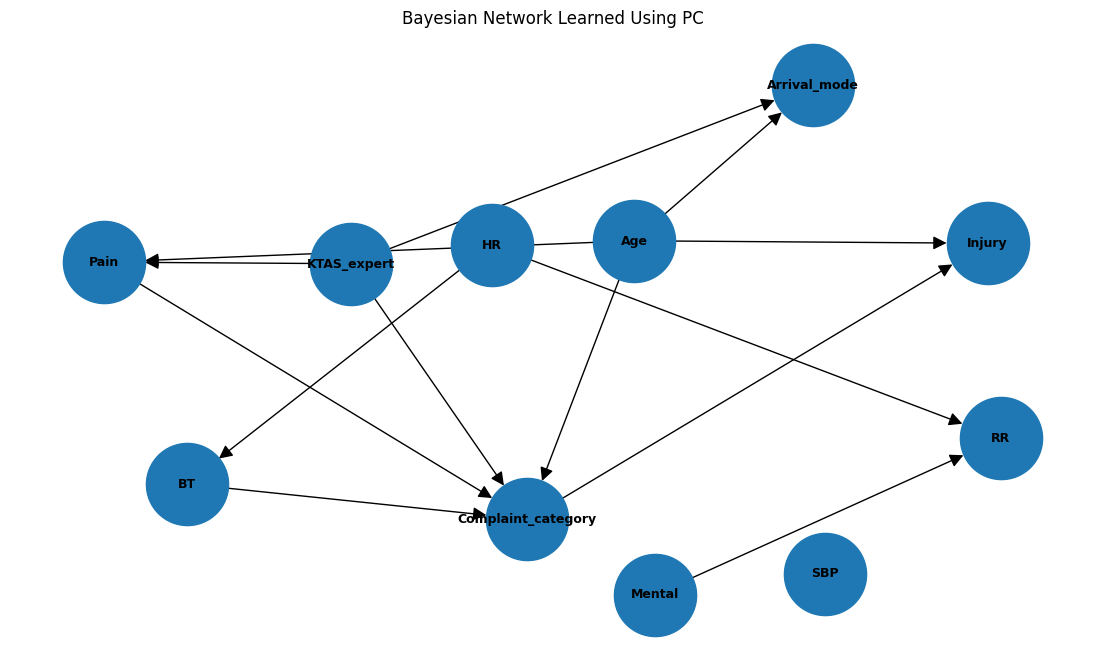

In [178]:
draw_bn(
    pc_model,
    "Bayesian Network Learned Using PC"
)

### PC Structure Summary

The PC algorithm learned a network containing 13 directed edges. In the learned structure, `KTAS_expert` has no direct parent nodes. Instead, it has directed edges toward `Complaint_category`, `Pain`, and `Arrival_mode`.

This differs substantially from the clinician-informed network, in which several clinical variables were specified as direct parents of `KTAS_expert`. The directions learned by the PC algorithm represent a DAG that is compatible with the conditional independence relationships identified in the training data and should not automatically be interpreted as causal or clinical directions.

### Model 2 — Hill Climb Search

Hill Climb Search is a score-based structure-learning method. Starting from an initial network, it iteratively considers local changes such as adding, deleting, or reversing edges and retains changes that improve the selected scoring criterion.

BIC is used as the scoring method to balance model fit against model complexity.

In [179]:
hc = HillClimbSearch(pc_data)

hc_structure = hc.estimate(
    scoring_method=BIC(pc_data),
    show_progress=False
)

hc_model = DiscreteBayesianNetwork(
    hc_structure.edges()
)

hc_model.add_nodes_from(
    pc_data.columns
)

print("Hill Climb edges:")
print(list(hc_model.edges()))

print("\nNumber of edges:")
print(len(hc_model.edges()))

print("\nParents of KTAS_expert:")
print(
    list(
        hc_model.predecessors(
            "KTAS_expert"
        )
    )
)

/tmp/ipykernel_3821/2294867530.py:1: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  hc = HillClimbSearch(pc_data)


Hill Climb edges:
[('Complaint_category', 'Pain'), ('Complaint_category', 'KTAS_expert'), ('Pain', 'Mental'), ('KTAS_expert', 'Arrival_mode'), ('KTAS_expert', 'RR'), ('Injury', 'Complaint_category'), ('Injury', 'Age'), ('HR', 'BT'), ('RR', 'HR')]

Number of edges:
9

Parents of KTAS_expert:
['Complaint_category']


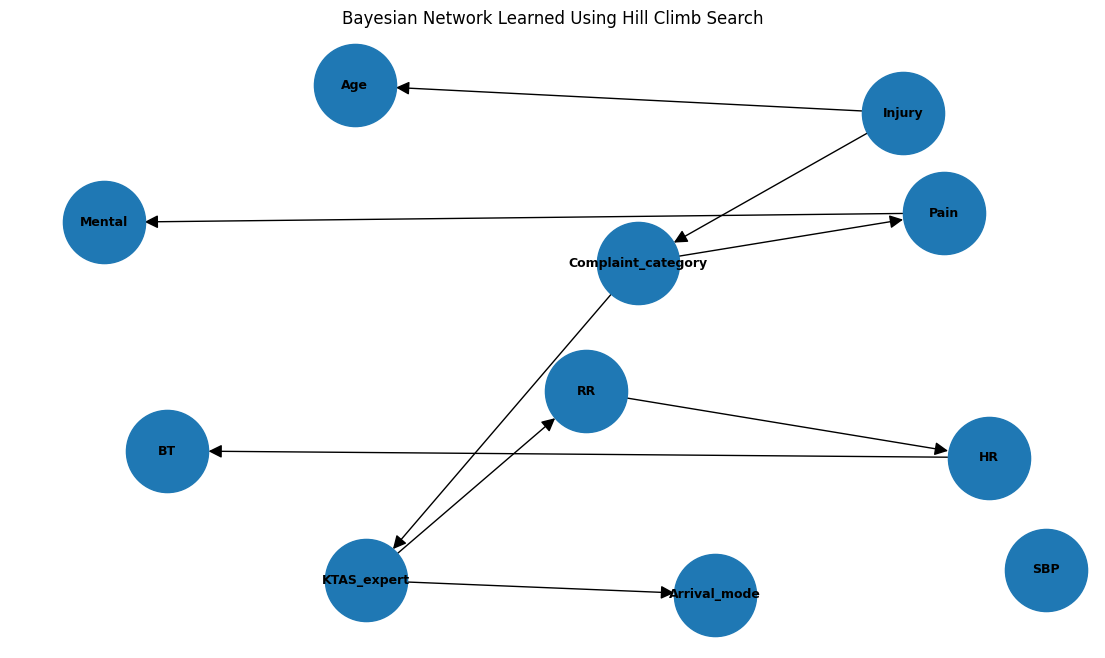

In [180]:
draw_bn(
    hc_model,
    "Bayesian Network Learned Using Hill Climb Search"
)

### Model 3 — Tree Search

Tree Search learns a tree-structured Bayesian Network. The Chow-Liu algorithm constructs a maximum-weight spanning tree based on pairwise mutual information between variables.

Because a tree structure is restricted to connecting variables without additional cycles, it is generally simpler than an unrestricted Bayesian Network.

In [181]:
tree = TreeSearch(pc_data)

tree_structure = tree.estimate(
    estimator_type="chow-liu",
    show_progress=False
)

tree_model = DiscreteBayesianNetwork(
    tree_structure.edges()
)

tree_model.add_nodes_from(
    pc_data.columns
)

print("Tree Search edges:")
print(list(tree_model.edges()))

print("\nNumber of edges:")
print(len(tree_model.edges()))

print("\nParents of KTAS_expert:")
print(
    list(
        tree_model.predecessors(
            "KTAS_expert"
        )
    )
)

Tree Search edges:
[('Complaint_category', 'Injury'), ('Complaint_category', 'Pain'), ('Complaint_category', 'KTAS_expert'), ('Complaint_category', 'Arrival_mode'), ('Complaint_category', 'BT'), ('Complaint_category', 'Age'), ('Complaint_category', 'RR'), ('Complaint_category', 'SBP'), ('Arrival_mode', 'Mental'), ('BT', 'HR')]

Number of edges:
10

Parents of KTAS_expert:
['Complaint_category']


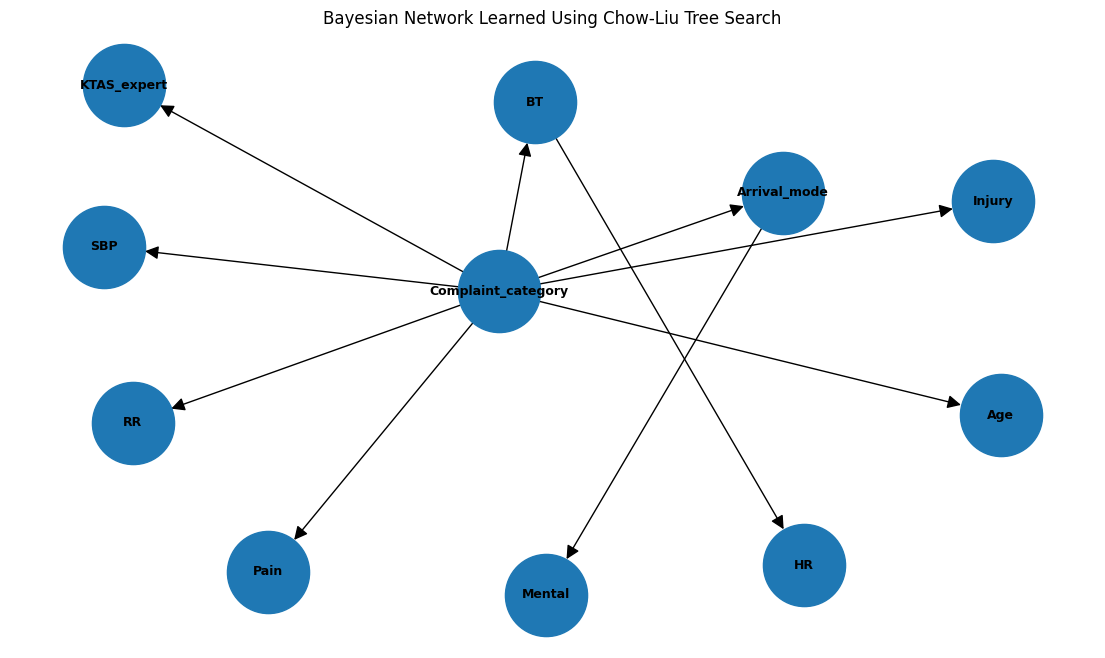

In [182]:
draw_bn(
    tree_model,
    "Bayesian Network Learned Using Chow-Liu Tree Search"
)

In [183]:
model_summary = pd.DataFrame({
    "Model": [
        "PC",
        "Hill Climb Search",
        "Tree Search"
    ],
    "Number of Edges": [
        len(pc_model.edges()),
        len(hc_model.edges()),
        len(tree_model.edges())
    ],
    "Parents of KTAS_expert": [
        list(pc_model.predecessors("KTAS_expert")),
        list(hc_model.predecessors("KTAS_expert")),
        list(tree_model.predecessors("KTAS_expert"))
    ]
})

display(model_summary)

,Model,Number of Edges,Parents of KTAS_expert
0,PC,13,[]
1,Hill Climb Search,9,[Complaint_category]
2,Tree Search,10,[Complaint_category]


In [184]:
# Directed edge sets
pc_edges = set(pc_model.edges())
hc_edges = set(hc_model.edges())
tree_edges = set(tree_model.edges())

print("Shared directed edges between PC and Hill Climb:")
print(pc_edges & hc_edges)

print("\nShared directed edges between PC and Tree Search:")
print(pc_edges & tree_edges)

print("\nShared directed edges between Hill Climb and Tree Search:")
print(hc_edges & tree_edges)

Shared directed edges between PC and Hill Climb:
{('HR', 'BT'), ('KTAS_expert', 'Arrival_mode')}

Shared directed edges between PC and Tree Search:
{('Complaint_category', 'Injury')}

Shared directed edges between Hill Climb and Tree Search:
{('Complaint_category', 'KTAS_expert'), ('Complaint_category', 'Pain')}


In [185]:
def get_adjacencies(model):
    return {
        frozenset([u, v])
        for u, v in model.edges()
    }

pc_adj = get_adjacencies(pc_model)
hc_adj = get_adjacencies(hc_model)
tree_adj = get_adjacencies(tree_model)

print("Shared adjacencies between PC and Hill Climb:")
print(pc_adj & hc_adj)

print("\nShared adjacencies between PC and Tree Search:")
print(pc_adj & tree_adj)

print("\nShared adjacencies between Hill Climb and Tree Search:")
print(hc_adj & tree_adj)

Shared adjacencies between PC and Hill Climb:
{frozenset({'Complaint_category', 'Pain'}), frozenset({'Complaint_category', 'KTAS_expert'}), frozenset({'HR', 'RR'}), frozenset({'Injury', 'Age'}), frozenset({'Injury', 'Complaint_category'}), frozenset({'BT', 'HR'}), frozenset({'Arrival_mode', 'KTAS_expert'})}

Shared adjacencies between PC and Tree Search:
{frozenset({'Complaint_category', 'Pain'}), frozenset({'Complaint_category', 'BT'}), frozenset({'Complaint_category', 'KTAS_expert'}), frozenset({'Complaint_category', 'Age'}), frozenset({'Injury', 'Complaint_category'}), frozenset({'BT', 'HR'})}

Shared adjacencies between Hill Climb and Tree Search:
{frozenset({'Complaint_category', 'Pain'}), frozenset({'Injury', 'Complaint_category'}), frozenset({'Complaint_category', 'KTAS_expert'}), frozenset({'BT', 'HR'})}


### Comparison of Learned Structures

The three structure-learning methods produced noticeably different Bayesian Network structures. The PC algorithm learned the densest network with 13 edges, Hill Climb Search learned the sparsest network with 9 edges, and Chow-Liu Tree Search produced 10 edges. The 10-edge Tree Search result is consistent with a spanning tree over the 11 variables.

The learned relationships involving `KTAS_expert` differed across the methods. In the PC network, `KTAS_expert` had no direct parents and instead had outgoing edges to `Complaint_category`, `Pain`, and `Arrival_mode`. In contrast, both Hill Climb Search and Tree Search identified `Complaint_category` as the only direct parent of `KTAS_expert`.

When both adjacency and direction are considered, relatively few edges are identical across the methods. PC and Hill Climb share the directed edges `HR → BT` and `KTAS_expert → Arrival_mode`. PC and Tree Search share `Complaint_category → Injury`, while Hill Climb and Tree Search share `Complaint_category → KTAS_expert` and `Complaint_category → Pain`.

When edge direction is ignored, there is considerably more agreement among the learned structures. All three algorithms identify direct relationships between `Complaint_category` and `Pain`, between `Complaint_category` and `KTAS_expert`, between `Complaint_category` and `Injury`, and between `BT` and `HR`. These relationships therefore appear relatively consistently across the three different structure-learning approaches.

The differences in edge orientation and overall structure are expected because the algorithms use different learning strategies. PC relies on conditional independence tests, Hill Climb Search optimizes a network score, and Chow-Liu restricts the network to a tree structure. Therefore, the learned directions should be interpreted as components of the statistical models rather than necessarily as causal clinical relationships.

Compared with the clinician-informed network, which contains 13 edges
and ten direct parents of `KTAS_expert`, the learned networks represent
the outcome using substantially different local structures. PC also
has 13 edges, but `KTAS_expert` has no parents. Hill Climb and Tree Search
have 9 and 10 edges, respectively, with `Complaint_category` as the only
direct parent of `KTAS_expert`.

Thus, equal edge counts do not imply equivalent networks. The
clinician-informed model encodes the specified domain assumptions,
whereas the learned networks reflect the training data and the
constraints or scoring criteria of each algorithm.

### Parameter Learning for the Learned Networks

After learning the three network structures from the training data, conditional probability tables are estimated using the same training dataset. Maximum Likelihood Estimation is used because the learned structures are substantially sparser than the clinician-informed network.

In [186]:
# Fit CPTs using Maximum Likelihood Estimation (MLE).
# MLE is the default parameter estimator for
# DiscreteBayesianNetwork.fit().

pc_model.fit(pc_data)
hc_model.fit(pc_data)
tree_model.fit(pc_data)

print("PC model valid:", pc_model.check_model())
print("Hill Climb model valid:", hc_model.check_model())
print("Tree Search model valid:", tree_model.check_model())

PC model valid: True
Hill Climb model valid: True
Tree Search model valid: True


In [187]:
pc_ktas_cpd = pc_model.get_cpds("KTAS_expert")

pc_cpt = pd.DataFrame({
    "KTAS_expert": pc_ktas_cpd.state_names["KTAS_expert"],
    "Probability": pc_ktas_cpd.get_values().flatten()
})

print("PC Model - CPT for KTAS_expert")
display(pc_cpt)

PC Model - CPT for KTAS_expert


,KTAS_expert,Probability
0,emergency,0.564777
1,non_emergency,0.435223


In [188]:
hc_ktas_cpd = hc_model.get_cpds("KTAS_expert")

hc_values = hc_ktas_cpd.get_values()

hc_cpt = pd.DataFrame(
    hc_values,
    index=hc_ktas_cpd.state_names["KTAS_expert"],
    columns=hc_ktas_cpd.state_names["Complaint_category"]
)

print("Hill Climb Model - CPT for KTAS_expert")
display(hc_cpt.T.round(6))

Hill Climb Model - CPT for KTAS_expert


,emergency,non_emergency
abdominal,0.569061,0.430939
bleeding,0.840909,0.159091
chest_cardiovascular,0.918605,0.081395
fever_infection,0.526316,0.473684
gastrointestinal,0.586207,0.413793
general_other,0.384615,0.615385
genitourinary,0.333333,0.666667
musculoskeletal_pain,0.179487,0.820513
neurologic,0.852564,0.147436
respiratory,0.963636,0.036364


In [189]:
tree_ktas_cpd = tree_model.get_cpds("KTAS_expert")

tree_values = tree_ktas_cpd.get_values()

tree_cpt = pd.DataFrame(
    tree_values,
    index=tree_ktas_cpd.state_names["KTAS_expert"],
    columns=tree_ktas_cpd.state_names["Complaint_category"]
)

print("Tree Search Model - CPT for KTAS_expert")
display(tree_cpt.T.round(6))

Tree Search Model - CPT for KTAS_expert


,emergency,non_emergency
abdominal,0.569061,0.430939
bleeding,0.840909,0.159091
chest_cardiovascular,0.918605,0.081395
fever_infection,0.526316,0.473684
gastrointestinal,0.586207,0.413793
general_other,0.384615,0.615385
genitourinary,0.333333,0.666667
musculoskeletal_pain,0.179487,0.820513
neurologic,0.852564,0.147436
respiratory,0.963636,0.036364


### CPT Comparison

The form of the `KTAS_expert` CPT reflects the structure learned by each algorithm. In the PC network, `KTAS_expert` has no parent variables. Its CPT therefore represents an unconditional probability distribution, with an estimated training-set probability of 0.5648 for Emergency and 0.4352 for Non-Emergency.

In both the Hill Climb and Tree Search networks, `Complaint_category` is the only direct parent of `KTAS_expert`. Their CPTs therefore represent $$
P(KTAS\_expert \mid Complaint\_category)
$$, allowing the probability of Emergency classification to vary according to the patient's complaint category.

The simpler CPTs in these learned networks contrast with the clinician-informed network, where `KTAS_expert` has many direct parents and consequently requires a much larger conditional probability table.

The Hill Climb and Tree Search CPTs for `KTAS_expert` are identical here
because both models assign the same parent to this node and estimate
its parameters using MLE on the same training data. Their overall
networks and BIC scores can nevertheless differ because other nodes
have different parent sets.

# Problem 4 — Model Comparison Using BIC

The three structures learned from the training data are scored using
pgmpy's BIC structure-scoring functionality on the validation data,
as requested in the assignment.

The score combines a likelihood term based on validation-data counts
with a penalty for structural complexity. This evaluates the learned
structures; it does not directly evaluate the predictive likelihood
of the CPTs fitted on the training data.

In [190]:
validation_clean = validation_data.copy()

for col in validation_clean.columns:
    if isinstance(
        validation_clean[col].dtype,
        pd.CategoricalDtype
    ):
        validation_clean[col] = (
            validation_clean[col].astype(str)
        )

print("Validation observations:", len(validation_clean))

Validation observations: 248


In [191]:
validation_bic = BIC(validation_clean)

pc_bic = validation_bic.score(pc_model)
hc_bic = validation_bic.score(hc_model)
tree_bic = validation_bic.score(tree_model)

bic_results = pd.DataFrame({
    "Model": [
        "PC",
        "Hill Climb Search",
        "Tree Search"
    ],
    "BIC Score": [
        pc_bic,
        hc_bic,
        tree_bic
    ]
})

bic_results = bic_results.sort_values(
    "BIC Score",
    ascending=False
).reset_index(drop=True)

display(bic_results)

,Model,BIC Score
0,Hill Climb Search,-2282.829697
1,Tree Search,-2558.923732
2,PC,-3288.407047


In [192]:
best_model = bic_results.iloc[0]

print(
    "Best model:",
    best_model["Model"]
)

print(
    "Best validation BIC score:",
    round(best_model["BIC Score"], 2)
)

Best model: Hill Climb Search
Best validation BIC score: -2282.83


### BIC Comparison and Scoring Convention

Hill Climb Search achieved the highest score (-2282.83), followed by
Tree Search (-2558.92) and PC (-3288.41).

The traditional BIC is:

$$
BIC_{\mathrm{traditional}} = -2\log\hat{L} + k\log n
$$

The pgmpy scoring convention used here is:

$$
S_{\mathrm{pgmpy}} = \log\hat{L} - \frac{k}{2}\log n
= -\frac{1}{2}BIC_{\mathrm{traditional}}
$$

Therefore, a higher pgmpy score is preferred, whereas a lower traditional
BIC is preferred. Hill Climb Search is the preferred structure under
this validation-data scoring criterion.

Here, k is the number of free parameters, not simply the number of
edges. The complexity penalty depends on parent configurations and
variable cardinalities. Consequently, Hill Climb's better score should
not be attributed solely to its smaller edge count.

In [193]:
final_comparison = pd.DataFrame({
    "Model": [
        "PC",
        "Hill Climb Search",
        "Tree Search"
    ],
    "Number of Edges": [
        len(pc_model.edges()),
        len(hc_model.edges()),
        len(tree_model.edges())
    ],
    "Parents of KTAS_expert": [
    ", ".join(pc_model.predecessors("KTAS_expert")) or "None",
    ", ".join(hc_model.predecessors("KTAS_expert")) or "None",
    ", ".join(tree_model.predecessors("KTAS_expert")) or "None"
],
    "Validation BIC": [
        pc_bic,
        hc_bic,
        tree_bic
    ]
})

final_comparison = final_comparison.sort_values(
    "Validation BIC",
    ascending=False
).reset_index(drop=True)

display(final_comparison)

,Model,Number of Edges,Parents of KTAS_expert,Validation BIC
0,Hill Climb Search,9,Complaint_category,-2282.829697
1,Tree Search,10,Complaint_category,-2558.923732
2,PC,13,None,-3288.407047


## Conclusion

This analysis applied Bayesian Networks to model emergency triage classification using demographic, clinical, and presentation-related variables.

The clinician-informed Bayesian Network encoded the relationships specified in the assignment and allowed probabilistic inference for `KTAS_expert`. The model estimated a baseline Emergency probability of 0.5228, compared with an observed complete-case proportion of 0.5712. For the example patient, the posterior probability of Emergency was 0.5131 when all specified evidence was available. When HR and RR were treated as missing, the probability changed only slightly to 0.5188, demonstrating how Bayesian Networks can perform inference by marginalizing over unobserved variables.

Three alternative structures were then learned from the training data. PC produced 13 edges, Hill Climb Search produced 9 edges, and Chow-Liu Tree Search produced 10 edges. Although the algorithms differed in edge orientation and overall structure, all three identified direct relationships between complaint category and pain, complaint category and KTAS classification, complaint category and injury, and body temperature and heart rate.

When the three learned structures were scored on the validation data
using pgmpy's BIC structure score, Hill Climb Search achieved the highest
score (-2282.83), followed by Tree Search (-2558.92) and PC (-3288.41).
Hill Climb Search was therefore preferred under this criterion. This
comparison concerns network structure fit and complexity and does not
establish classification accuracy or clinical usefulness.

Overall, the analysis demonstrates both the interpretability and flexibility of Bayesian Networks for clinical triage data. At the same time, the differences between the clinician-informed and data-learned structures highlight that statistically learned relationships and edge directions should not automatically be interpreted as causal clinical relationships.